# Deterministic Loading Sweep Analysis

Quantitative analysis for `AtomLoadDeterministicTest` sweep data (e.g., `t_MOT2PGC`).

**Workflow**
1. Run the test experiment on the dashboard for each sweep point. Each run writes one HDF5 to `repository/results/<date>/<hour>/<RID>-AtomLoadDeterministicTest.h5`.
2. Edit the **FILES** list in Cell 2 with the paths.
3. Run all cells top-to-bottom. Re-run the analysis cell after adding more sweep points.

**What you get**
- Apparent loading rate (loader's self-report) + 95% Wilson CI
- Confirmed loading rate (loader yes AND confirmation > bg + 3sigma) + CI
- Missed-load rate (loader no but atom actually present) + CI
- False-positive rate among reported successes
- Per-file confirmation/background medians, gap, threshold
- Plots: rates vs sweep parameter, confirmation/bg medians vs sweep parameter, per-file histograms

## Setup

In [7]:
import sys, os
sys.path.insert(0, r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from analysis.data_loader import load
from analysis.analyze_loading_sweep import analyze_one, wilson_ci, mad_robust_sigma

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', lambda v: f'{v:.3f}')
print('Setup complete.')

Setup complete.


## 1. Edit the sweep file list

Hardcode each HDF5 file path below. Order doesn't matter — the analysis sorts by `t_MOT2PGC` automatically. Comment out lines (with `#`) to exclude a run.

Each file's swept parameter value is read from the `det_t_MOT2PGC_used` dataset inside the HDF5, so you don't need to label the files — the labels come from the data itself.

In [8]:
############################################################################
# EDIT THIS: one entry per sweep point
############################################################################
FILES = [
    r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-05-19\17\000000232-AtomLoadDeterministicTest.h5",
    r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-05-19\22\000000249-AtomLoadDeterministicTest.h5",
    r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-05-19\22\000000250-AtomLoadDeterministicTest.h5",
    r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-05-19\22\000000251-AtomLoadDeterministicTest.h5",
    r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-05-19\22\000000252-AtomLoadDeterministicTest.h5",
    r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-05-19\22\000000255-AtomLoadDeterministicTest.h5",
    r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-05-19\22\000000256-AtomLoadDeterministicTest.h5",
    # r"...add more lines like the above...",
    # r"...add more lines like the above...",
    # r"...add more lines like the above...",
]

# Which dataset to use as the sweep x-axis. Default sweeps t_MOT2PGC.
# Other options once you echo them from the test experiment:
#   det_t_PGC_2_off_used, det_t_MOT_dissipation_used, det_t_PGC_after_img_used, ...
X_KEY   = "det_t_MOT2PGC_used"
X_LABEL = "t_MOT2PGC (ms)"
X_SCALE = 1e3            # display scale: 1e3 for seconds->ms, 1e6 for s->us, 1.0 for unitless

# Confirmation threshold = bg_median + SIGMA * max(MAD, sqrt(bg_median))
SIGMA = 3.0
############################################################################

# Sanity check
missing = [f for f in FILES if not Path(f).exists()]
if missing:
    print(f'WARNING: {len(missing)} file(s) not found:')
    for f in missing:
        print(f'  {f}')
else:
    print(f'{len(FILES)} file(s) ready.')

7 file(s) ready.


## 2. Compute per-file metrics

Each file -> one row. Re-run this cell after editing **FILES** to refresh.

In [9]:
rows = []
for path in FILES:
    if not Path(path).exists():
        print(f'SKIP (not found): {path}')
        continue
    try:
        rows.append(analyze_one(path, x_key=X_KEY, sigma=SIGMA))
    except Exception as e:
        import traceback
        print(f'FAIL on {Path(path).name}: {type(e).__name__}: {e}')
        traceback.print_exc()

if not rows:
    raise RuntimeError('No usable files. Fix FILES list above.')

rows.sort(key=lambda r: r['x'])
print(f'Analyzed {len(rows)} file(s).')

Analyzed 7 file(s).


## 3. Summary table

| Column | Meaning |
|---|---|
| `apparent` | Loader's self-reported success (with 95% CI) |
| `confirmed` | Loader yes AND confirmation > threshold (the honest number) |
| `missed` | Loader no AND confirmation > threshold (loader gave up but atom was there) |
| `FP/app` | Of loader-reported successes, fraction that failed confirmation |
| `thresh` | Per-file confirmation threshold (counts per imaging gate) |
| `gap` | median(confirm) - median(bg), in counts |
| `t_load_ms` | Median time-to-detection (successful shots only) |
| `MOT_kcps` | First-try MOT-only rate per SPCM |
| `fb_rnds` | Mean feedback rounds per shot |

In [11]:
def fmt_ci(p, ci):
    lo, hi = ci
    return f'{p*100:5.1f} [{lo*100:4.1f}-{hi*100:4.1f}]'

def fmt_num(v, dec=1):
    # v != v is True only for NaN
    return '--' if v != v else f'{v:.{dec}f}'

# All display columns are preformatted as strings, then we show the plain
# DataFrame. Plain df rendering uses pandas' own _repr_html_, which needs no
# extra packages. df.style would require jinja2 (absent in artiq7_claude),
# which was the AttributeError.
df = pd.DataFrame([
    {
        X_LABEL:       fmt_num(r['x'] * X_SCALE),
        'N':           r['n_shots'],
        'apparent %':  fmt_ci(r['apparent_p'],  r['apparent_ci']),
        'confirmed %': fmt_ci(r['confirmed_p'], r['confirmed_ci']),
        'missed %':    fmt_ci(r['missed_p'],    r['missed_ci']),
        'FP/app %':    fmt_ci(r['fp_p'],        r['fp_ci']),
        'thresh':      fmt_num(r['atom_threshold']),
        'gap':         fmt_num(r['gap_counts']),
        'bg':          fmt_num(r['bg_med']),
        'conf':        fmt_num(r['confirm_med']),
        't_load_ms':   fmt_num(r['t_load_med_ms']),
        'MOT_kcps':    fmt_num(r['mot_only_rate_kcps'], 2),
        'fb_rnds':     fmt_num(r['mean_fb_rounds'], 2),
    }
    for r in rows
])
df

,t_MOT2PGC (ms),N,apparent %,confirmed %,missed %,FP/app %,thresh,gap,bg,conf,t_load_ms,MOT_kcps,fb_rnds
0,10.0,100,100.0 [96.3-100.0],98.0 [93.0-99.4],0.0 [ 0.0- 3.7],2.0 [ 0.6- 7.0],10.0,38.0,4.0,42.0,399.1,0.50,2.45
1,30.0,100,100.0 [96.3-100.0],96.0 [90.2-98.4],0.0 [ 0.0- 3.7],4.0 [ 1.6- 9.8],10.7,40.0,4.0,44.0,229.9,0.60,0.94
2,50.0,100,100.0 [96.3-100.0],100.0 [96.3-100.0],0.0 [ 0.0- 3.7],0.0 [ 0.0- 3.7],14.9,38.5,6.0,44.5,151.6,0.80,0.23
3,100.0,100,100.0 [96.3-100.0],96.0 [90.2-98.4],0.0 [ 0.0- 3.7],4.0 [ 1.6- 9.8],14.9,41.0,6.0,47.0,60.7,1.10,0.00
4,200.0,100,100.0 [96.3-100.0],83.0 [74.5-89.1],0.0 [ 0.0- 3.7],17.0 [10.9-25.5],20.3,38.0,7.0,45.0,5.2,5.40,0.00
5,300.0,100,100.0 [96.3-100.0],75.0 [65.7-82.5],0.0 [ 0.0- 3.7],25.0 [17.5-34.3],15.9,35.5,7.0,42.5,5.2,4.95,0.00
6,400.0,100,100.0 [96.3-100.0],85.0 [76.7-90.7],0.0 [ 0.0- 3.7],15.0 [ 9.3-23.3],14.9,36.0,6.0,42.0,5.2,5.15,0.00


## 4. Rate plot

Top: apparent / confirmed / missed rates vs the sweep parameter with 95% Wilson CIs.

Bottom: median confirmation counts vs median background, with the threshold band shaded — visualizes whether the discrimination is the bottleneck at any sweep point.

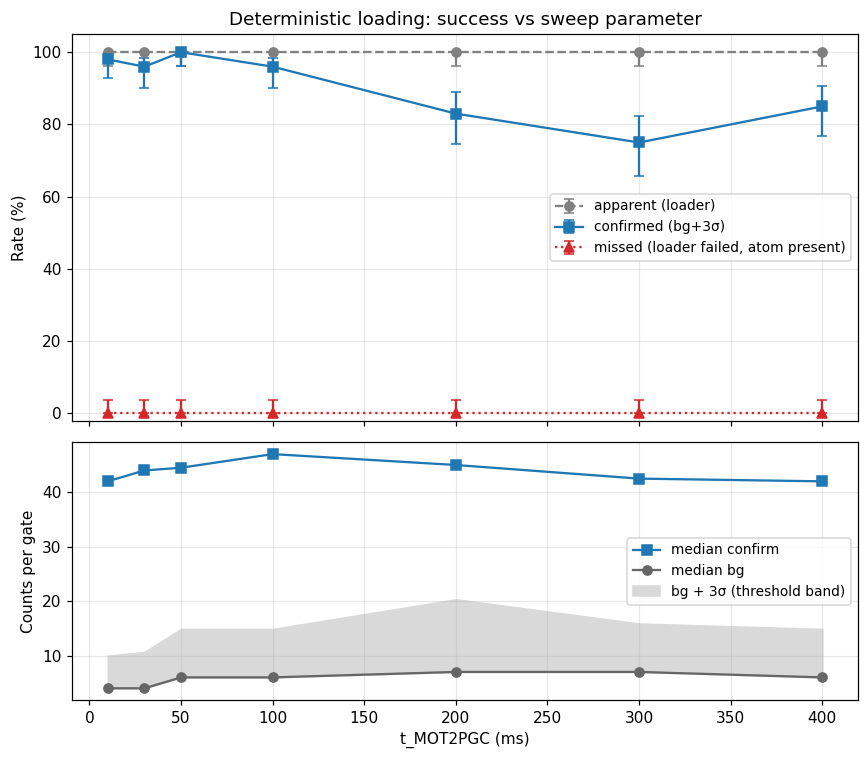

In [12]:
x = np.array([r['x'] * X_SCALE for r in rows])

def err_pair(rows, key):
    # Clamp to >= 0: the Wilson interval can put p a hair outside [lo, hi]
    # by floating-point noise, and matplotlib rejects negative yerr.
    p = np.array([r[key + '_p'] * 100 for r in rows])
    lo = np.clip(p - np.array([r[key + '_ci'][0] * 100 for r in rows]), 0, None)
    hi = np.clip(np.array([r[key + '_ci'][1] * 100 for r in rows]) - p, 0, None)
    return p, [lo, hi]

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(8, 7), sharex=True,
    gridspec_kw={'height_ratios': [3, 2]}
)

ap, ap_e = err_pair(rows, 'apparent')
co, co_e = err_pair(rows, 'confirmed')
mi, mi_e = err_pair(rows, 'missed')

ax_top.errorbar(x, ap, yerr=ap_e, fmt='o--', color='gray',
                label='apparent (loader)', capsize=3)
ax_top.errorbar(x, co, yerr=co_e, fmt='s-', color='C0',
                label=f'confirmed (bg+{SIGMA:.0f}σ)', capsize=3)
ax_top.errorbar(x, mi, yerr=mi_e, fmt='^:', color='C3',
                label='missed (loader failed, atom present)', capsize=3)
ax_top.set_ylabel('Rate (%)')
ax_top.set_ylim(-2, 105)
ax_top.grid(alpha=0.3)
ax_top.legend(loc='best', fontsize=9)
ax_top.set_title('Deterministic loading: success vs sweep parameter')

thr = np.array([r['atom_threshold'] - r['bg_med'] for r in rows])
confirm_med = np.array([r['confirm_med'] for r in rows])
bg_med = np.array([r['bg_med'] for r in rows])

ax_bot.plot(x, confirm_med, 's-', color='C0', label='median confirm')
ax_bot.plot(x, bg_med, 'o-', color='0.4', label='median bg')
ax_bot.fill_between(x, bg_med, bg_med + thr, color='0.85',
                    label=f'bg + {SIGMA:.0f}σ (threshold band)')
ax_bot.set_xlabel(X_LABEL)
ax_bot.set_ylabel('Counts per gate')
ax_bot.grid(alpha=0.3)
ax_bot.legend(loc='best', fontsize=9)

fig.tight_layout()
plt.show()

## 5. Per-file confirmation histograms (drill-down)

One overlaid histogram per sweep point: cyan = background (no atom), red = confirmation (loader said success). The threshold line shows where this analysis split atom vs background.

If red overlaps cyan or sits at the threshold line, the apparent success rate at that sweep point is contaminated by false positives — trust the confirmed-rate column over the apparent-rate column.

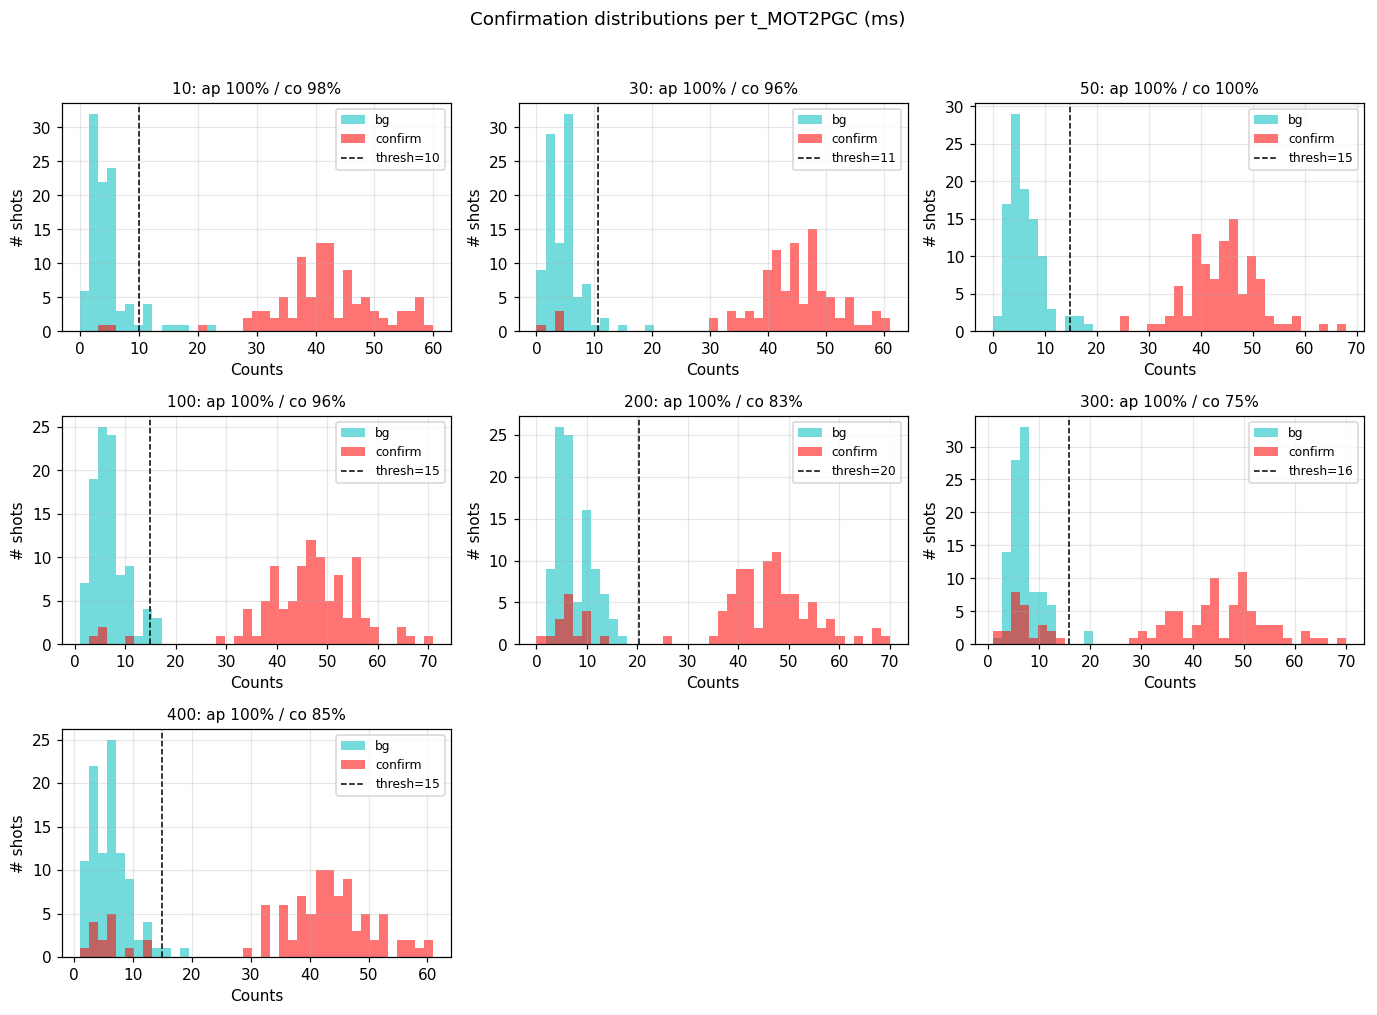

In [13]:
# Reload each file, sort by x, then plot one histogram per sweep point.
existing_files = [f for f in FILES if Path(f).exists()]
file_pairs = []
for f in existing_files:
    bundle = load(f)
    file_pairs.append((float(bundle['data'][X_KEY]), bundle))
file_pairs.sort(key=lambda t: t[0])

n = len(file_pairs)
ncols = min(n, 3)
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(4.2 * ncols, 3.0 * nrows),
                         squeeze=False)

for i, (xv, bundle) in enumerate(file_pairs):
    ax = axes[i // ncols][i % ncols]
    d = bundle['data']
    bg = np.asarray(d['det_confirm_bg1'], dtype=float) + np.asarray(d['det_confirm_bg2'], dtype=float)
    co = np.asarray(d['det_confirm_count1'], dtype=float) + np.asarray(d['det_confirm_count2'], dtype=float)

    bg_med = float(np.median(bg)) if len(bg) else 0.0
    bg_sigma = mad_robust_sigma(bg)
    thr = bg_med + SIGMA * max(bg_sigma, float(np.sqrt(max(bg_med, 1.0))))

    lo = float(min(np.min(bg) if len(bg) else 0, np.min(co) if len(co) else 0))
    hi = float(max(np.max(bg) if len(bg) else 1, np.max(co) if len(co) else 1))
    if hi <= lo:
        hi = lo + 1.0
    edges = np.linspace(lo, hi, 40)

    if len(bg) > 0:
        ax.hist(bg, bins=edges, color='c', alpha=0.55, label='bg')
    if len(co) > 0:
        ax.hist(co, bins=edges, color='r', alpha=0.55, label='confirm')
    ax.axvline(thr, color='k', ls='--', lw=1.0, label=f'thresh={thr:.0f}')

    ap_pct = rows[i]['apparent_p'] * 100
    co_pct = rows[i]['confirmed_p'] * 100
    ax.set_title(f'{xv * X_SCALE:.0f}: ap {ap_pct:.0f}% / co {co_pct:.0f}%', fontsize=10)
    ax.set_xlabel('Counts')
    ax.set_ylabel('# shots')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.3)

for j in range(n, nrows * ncols):
    axes[j // ncols][j % ncols].axis('off')

fig.suptitle(f'Confirmation distributions per {X_LABEL}', y=1.02)
fig.tight_layout()
plt.show()

## 6. Save summary (optional)

Write the table to CSV for sharing or for plotting in another tool.

In [ ]:
CSV_OUT = r'C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\analysis_results\t_MOT2PGC_sweep_summary.csv'

# Build a CSV-friendly DataFrame (numeric columns only, no CI strings)
csv_df = pd.DataFrame([
    {
        'file':                r['file'],
        X_LABEL:               r['x'] * X_SCALE,
        'n_shots':             r['n_shots'],
        'apparent_p':          r['apparent_p'],
        'apparent_ci_lo':      r['apparent_ci'][0],
        'apparent_ci_hi':      r['apparent_ci'][1],
        'confirmed_p':         r['confirmed_p'],
        'confirmed_ci_lo':     r['confirmed_ci'][0],
        'confirmed_ci_hi':     r['confirmed_ci'][1],
        'missed_p':            r['missed_p'],
        'missed_ci_lo':        r['missed_ci'][0],
        'missed_ci_hi':        r['missed_ci'][1],
        'fp_p':                r['fp_p'],
        'fp_ci_lo':            r['fp_ci'][0],
        'fp_ci_hi':            r['fp_ci'][1],
        'bg_med':              r['bg_med'],
        'bg_sigma':            r['bg_sigma'],
        'atom_threshold':      r['atom_threshold'],
        'confirm_med':         r['confirm_med'],
        'gap_counts':          r['gap_counts'],
        't_load_med_ms':       r['t_load_med_ms'],
        'mot_only_med':        r['mot_only_med'],
        'mot_only_rate_kcps':  r['mot_only_rate_kcps'],
        'mean_fb_rounds':      r['mean_fb_rounds'],
        'threshold_rate_cps':  r['threshold_rate_cps'],
        'gate_time_s':         r['gate_time_s'],
    }
    for r in rows
])

Path(CSV_OUT).parent.mkdir(parents=True, exist_ok=True)
csv_df.to_csv(CSV_OUT, index=False)
print(f'CSV saved: {CSV_OUT}')
csv_df